In [1]:
# MNIST 데이터셋 불러오기
from tensorflow.keras.datasets import mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 [==============================] - 2s 0us/step


In [2]:
x_train.shape

(60000, 28, 28)

In [3]:
x_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [4]:
y_train.shape

(60000,)

In [5]:
y_train

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

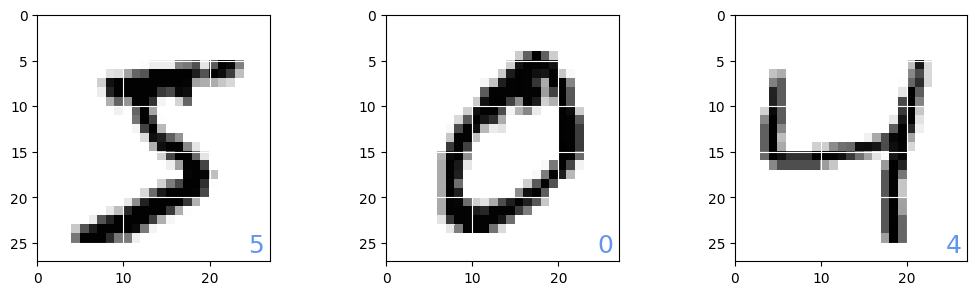

In [6]:
# week12_1.txt
import numpy as np
import matplotlib.pyplot as plt 
%matplotlib inline

plt.figure(1, figsize=(12, 3.2)) 
plt.subplots_adjust(wspace=0.5) 
plt.gray()

for id in range(3):
    plt.subplot(1, 3, id + 1)
    img = x_train[id, :, :]
    plt.pcolor(255 - img)
    plt.text(24.5, 26, "%d" % y_train[id],
             color='cornflowerblue', fontsize=18) 
    plt.xlim(0, 27)
    plt.ylim(27, 0)

    plt.grid('on', color='white') 
plt.show()

In [7]:
# one-hot encoding 을 위한 모듈 추가
from tensorflow.keras.utils import to_categorical
# 훈련(학습) 데이터 준비
x_train = x_train.reshape(60000, 784)
x_train = x_train.astype('float32')
x_train = x_train / 255
num_classes = 10
y_train = to_categorical(y_train, num_classes)
# 테스트 데이터 준비
x_test = x_test.reshape(10000, 784)
x_test = x_test.astype('float32')
x_test = x_test / 255
y_test = to_categorical(y_test, num_classes)

In [8]:
y_train[2]

array([0., 0., 0., 0., 1., 0., 0., 0., 0., 0.], dtype=float32)

In [9]:
# 필기체 숫자인식을 위한 2층 피드포워드 네트워크
# 은닉층 뉴런수 M=16개, 활성화 함수는 시그모이드 함수
# 출력층 뉴런수 K=10개, 활성화 함수는 소프트맥스 함수
import numpy as np
np.random.seed(1)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation
from tensorflow.keras.optimizers import Adam
model = Sequential()
model.add(Dense(16, input_dim=784, activation='sigmoid'))
model.add(Dense(10, activation='softmax'))
model.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])

In [10]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 16)                12560     
                                                                 
 dense_1 (Dense)             (None, 10)                170       
                                                                 
Total params: 12,730
Trainable params: 12,730
Non-trainable params: 0
_________________________________________________________________


In [11]:
# 학습
import time
start_time = time.time()
history = model.fit(x_train, y_train, epochs=10, batch_size=1000, verbose=1,
                    validation_data=(x_test, y_test))
print("computation time: {:.3f} sec".format(time.time() - start_time))

Epoch 1/10
43/60 [====================>.........] - ETA: 0s - loss: 2.0654 - accuracy: 0.3565

2026-06-20 15:25:43.023752: W tensorflow/core/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


60/60 [==============================] - 0s 2ms/step - loss: 1.9758 - accuracy: 0.4265 - val_loss: 1.6696 - val_accuracy: 0.6316
Epoch 2/10
60/60 [==============================] - 0s 1ms/step - loss: 1.5134 - accuracy: 0.7123 - val_loss: 1.3475 - val_accuracy: 0.7763
Epoch 3/10
60/60 [==============================] - 0s 2ms/step - loss: 1.2463 - accuracy: 0.7946 - val_loss: 1.1231 - val_accuracy: 0.8287
Epoch 4/10
60/60 [==============================] - 0s 2ms/step - loss: 1.0516 - accuracy: 0.8272 - val_loss: 0.9570 - val_accuracy: 0.8495
Epoch 5/10
60/60 [==============================] - 0s 2ms/step - loss: 0.9057 - accuracy: 0.8460 - val_loss: 0.8310 - val_accuracy: 0.8623
Epoch 6/10
60/60 [==============================] - 0s 2ms/step - loss: 0.7941 - accuracy: 0.8584 - val_loss: 0.7338 - val_accuracy: 0.8732
Epoch 7/10
60/60 [==============================] - 0s 2ms/step - loss: 0.7071 - accuracy: 0.8680 - val_loss: 0.6574 - val_accuracy: 0.8803
Epoch 8/10
60/60 [=============

In [12]:
# 평가
score = model.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

Test loss: 0.507477343082428
Test accuracy: 0.8955000042915344


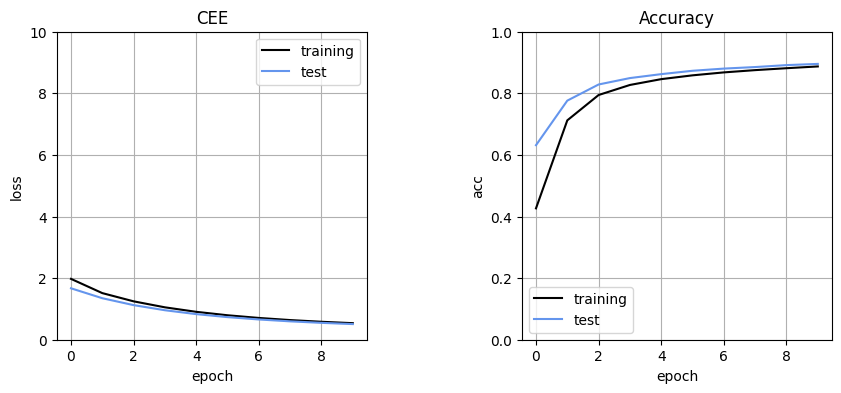

In [13]:
# week12_2.txt
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(1, figsize = (10, 4))
plt.subplots_adjust(wspace = 0.5)

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label = 'training', color = 'black')
plt.plot(history.history['val_loss'], label = 'test', color ='cornflowerblue')
plt.ylim(0, 10)
plt.legend()
plt.grid()
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('CEE')

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label = 'training', color = 'black')
plt.plot(history.history['val_accuracy'], label = 'test', color = 'cornflowerblue')
plt.ylim(0, 1)
plt.legend()
plt.grid()
plt.xlabel('epoch')
plt.ylabel('acc')
plt.title('Accuracy')
plt.show()

313/313 [==============================] - 0s 208us/step
Total wrong answer:  9 / 96


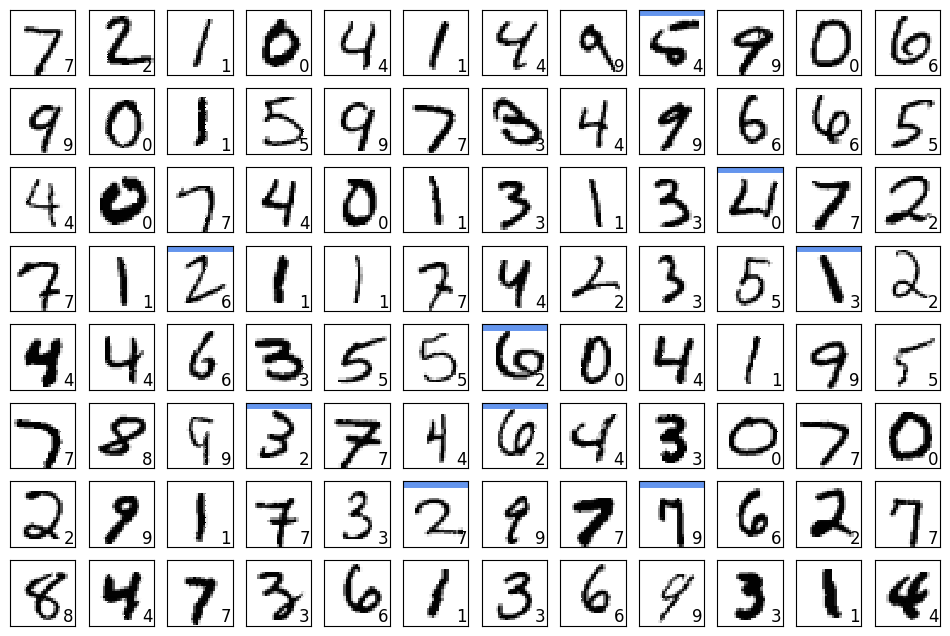

In [14]:
# week12_3.txt
# 실제 테스트 데이터를 입력했을 때 모델의 출력
def show_prediction():
    n_show = 96
    y = model.predict(x_test) # (A) x_test 전체에 대한 모델의 출력 y 를 얻을 수 있다.
    plt.figure(2, figsize = (12, 8))
    plt.gray()
    wrong_answer = 0
    for i in range(n_show):
        plt.subplot(8, 12, i + 1)
        x = x_test[i, :]
        x = x.reshape(28, 28)
        plt.pcolor(1 - x)
        wk = y[i, :]
        prediction = np.argmax(wk)
        plt.text(22, 25.5, "%d" % prediction, fontsize = 12)
        
        if prediction != np.argmax(y_test[i, :]):
            plt.plot([0, 27], [1, 1], color ='cornflowerblue', linewidth = 5)
            wrong_answer = wrong_answer + 1
            
        plt.xlim(0, 27)
        plt.ylim(27, 0)
        plt.xticks([], "")
        plt.yticks([], "")
    print("Total wrong answer: {0: d} / 96" .format(wrong_answer))
        
# 메인
show_prediction()
plt.show()

In [15]:
# week12_4.txt
# 실제 테스트 데이터를 입력했을 때 모델의 출력
model_relu = Sequential()
model_relu.add(Dense(16, input_dim=784, activation='relu'))
model_relu.add(Dense(10, activation='softmax'))
model_relu.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])
start_time = time.time()
history = model_relu.fit(x_train, y_train, epochs=10, batch_size=1000, verbose=1,
                         validation_data=(x_test, y_test))
print("computation time: {:.3f} sec".format(time.time() - start_time))

Epoch 1/10
60/60 [==============================] - 0s 2ms/step - loss: 1.4918 - accuracy: 0.5946 - val_loss: 0.8802 - val_accuracy: 0.7981
Epoch 2/10
60/60 [==============================] - 0s 2ms/step - loss: 0.6900 - accuracy: 0.8335 - val_loss: 0.5285 - val_accuracy: 0.8739
Epoch 3/10
60/60 [==============================] - 0s 2ms/step - loss: 0.4783 - accuracy: 0.8763 - val_loss: 0.4114 - val_accuracy: 0.8939
Epoch 4/10
60/60 [==============================] - 0s 2ms/step - loss: 0.3917 - accuracy: 0.8940 - val_loss: 0.3546 - val_accuracy: 0.9069
Epoch 5/10
60/60 [==============================] - 0s 2ms/step - loss: 0.3441 - accuracy: 0.9046 - val_loss: 0.3193 - val_accuracy: 0.9132
Epoch 6/10
60/60 [==============================] - 0s 2ms/step - loss: 0.3137 - accuracy: 0.9123 - val_loss: 0.2977 - val_accuracy: 0.9194
Epoch 7/10
60/60 [==============================] - 0s 2ms/step - loss: 0.2905 - accuracy: 0.9186 - val_loss: 0.2782 - val_accuracy: 0.9241
Epoch 8/10
60/60 [==

In [16]:
# 평가
score = model_relu.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

Test loss: 0.2435135692358017
Test accuracy: 0.9337000250816345


313/313 [==============================] - 0s 195us/step
Total wrong answer:  3 / 96


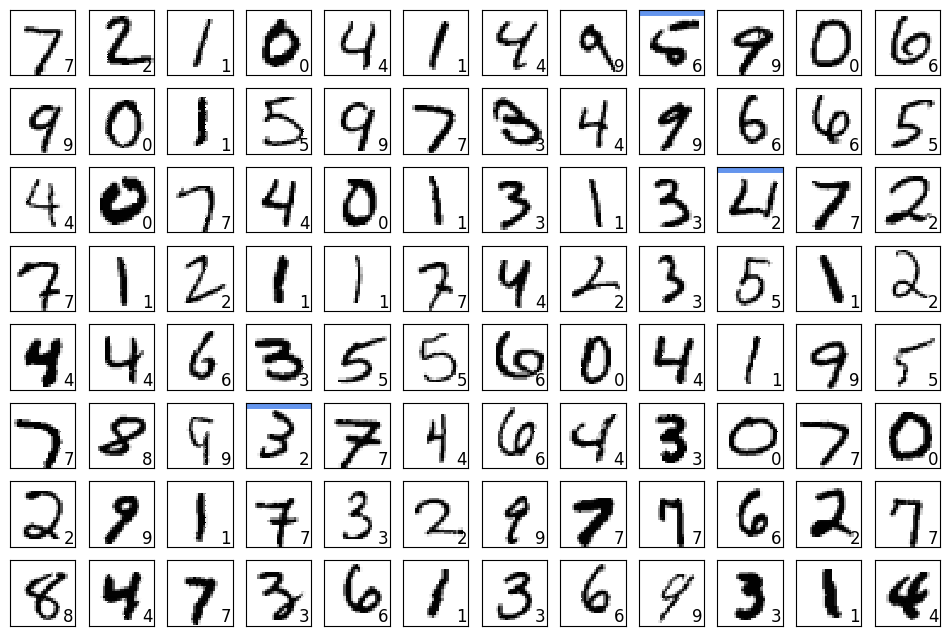

In [17]:
# week12_4.txt
# 실제 테스트 데이터를 입력했을 때 모델의 출력
def show_prediction():
    n_show = 96
    y = model_relu.predict(x_test)
    plt.figure(2, figsize = (12, 8))
    plt.gray()
    wrong_answer = 0
    for i in range(n_show):
        plt.subplot(8, 12, i + 1)
        x = x_test[i, :]
        x = x.reshape(28, 28)
        plt.pcolor(1 - x)
        wk = y[i, :]
        prediction = np.argmax(wk)
        plt.text(22, 25.5, "%d" % prediction, fontsize = 12)
        
        if prediction != np.argmax(y_test[i, :]):
            plt.plot([0, 27], [1, 1], color ='cornflowerblue', linewidth = 5)
            wrong_answer = wrong_answer + 1
            
        plt.xlim(0, 27)
        plt.ylim(27, 0)
        plt.xticks([], "")
        plt.yticks([], "")
    print("Total wrong answer: {0: d} / 96" .format(wrong_answer))
        
# 메인
show_prediction()
plt.show()

In [18]:
# MNIST 데이터셋 불러오기 (CNN용)
import numpy as np
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train.reshape(60000, 28, 28, 1)  # 데이터 하나의 shape (28, 28, 1)
x_train = x_train.astype('float32')
x_train = x_train / 255
x_test = x_test.reshape(10000, 28, 28, 1)
x_test = x_test.astype('float32')
x_test = x_test / 255
num_classes = 10
y_train = to_categorical(y_train, num_classes)
y_test = to_categorical(y_test, num_classes)

In [19]:
# 2층 합성곱 신경망 구현
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, Dense, Activation, Flatten
from tensorflow.keras.optimizers import Adam
np.random.seed(1)
model_cnn = Sequential()
model_cnn.add(Conv2D(8, (3, 3), padding='same',
                     input_shape=(28, 28, 1), activation='relu'))
model_cnn.add(Flatten())
model_cnn.add(Dense(10, activation='softmax'))
model_cnn.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])

In [20]:
model_cnn.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 8)         80        
                                                                 
 flatten (Flatten)           (None, 6272)              0         
                                                                 
 dense_4 (Dense)             (None, 10)                62730     
                                                                 
Total params: 62,810
Trainable params: 62,810
Non-trainable params: 0
_________________________________________________________________


In [21]:
import time
start_time = time.time()
history = model_cnn.fit(x_train, y_train, batch_size=1000, epochs=20, verbose=1,
                         validation_data=(x_test, y_test))
print("Computation time:{:.3f} sec".format(time.time() - start_time))

Epoch 1/20
60/60 [==============================] - 1s 23ms/step - loss: 1.0291 - accuracy: 0.7918 - val_loss: 0.3828 - val_accuracy: 0.8992
Epoch 2/20
60/60 [==============================] - 1s 22ms/step - loss: 0.3285 - accuracy: 0.9082 - val_loss: 0.2657 - val_accuracy: 0.9280
Epoch 3/20
60/60 [==============================] - 1s 21ms/step - loss: 0.2498 - accuracy: 0.9302 - val_loss: 0.2145 - val_accuracy: 0.9403
Epoch 4/20
60/60 [==============================] - 1s 21ms/step - loss: 0.2021 - accuracy: 0.9434 - val_loss: 0.1810 - val_accuracy: 0.9490
Epoch 5/20
60/60 [==============================] - 1s 22ms/step - loss: 0.1661 - accuracy: 0.9543 - val_loss: 0.1517 - val_accuracy: 0.9588
Epoch 6/20
60/60 [==============================] - 1s 22ms/step - loss: 0.1401 - accuracy: 0.9617 - val_loss: 0.1308 - val_accuracy: 0.9648
Epoch 7/20
60/60 [==============================] - 1s 21ms/step - loss: 0.1203 - accuracy: 0.9675 - val_loss: 0.1157 - val_accuracy: 0.9674
Epoch 8/20
60

In [22]:
score = model_cnn.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

Test loss: 0.0635182186961174
Test accuracy: 0.9814000129699707


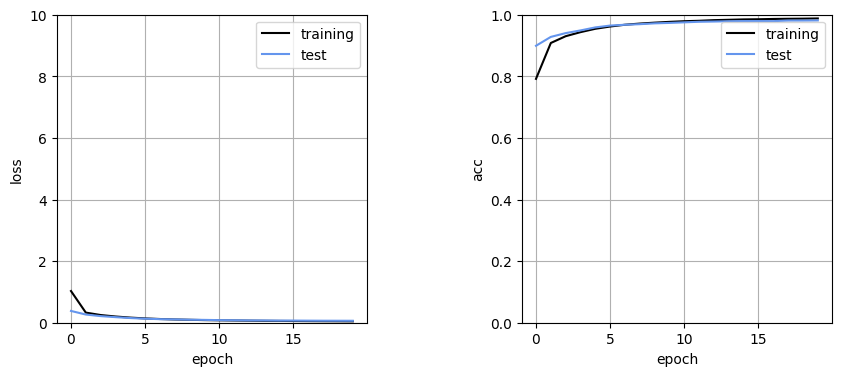

In [23]:
# week12_5.txt
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(1, figsize = (10, 4))
plt.subplots_adjust(wspace = 0.5)

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label = 'training', color = 'black')
plt.plot(history.history['val_loss'], label = 'test', color ='cornflowerblue')
plt.ylim(0, 10)
plt.legend()
plt.grid()
plt.xlabel('epoch')
plt.ylabel('loss')

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label = 'training', color = 'black')
plt.plot(history.history['val_accuracy'], label = 'test', color = 'cornflowerblue')
plt.ylim(0, 1)
plt.legend()
plt.grid()
plt.xlabel('epoch')
plt.ylabel('acc')
plt.show()

313/313 [==============================] - 0s 598us/step
Total wrong answer:  2 / 96


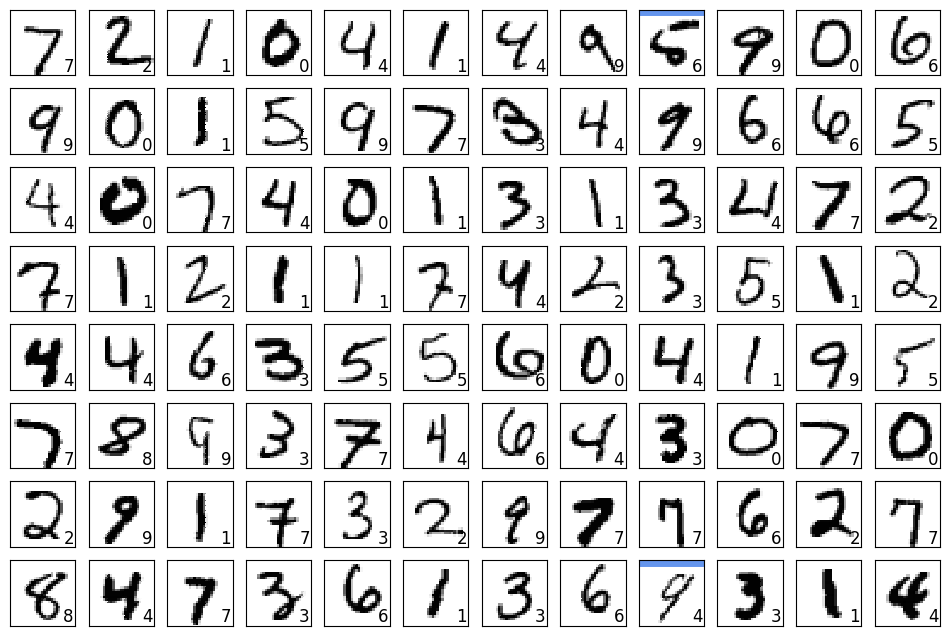

In [24]:
# week12_6.txt
# 실제 테스트 데이터를 입력했을 때 모델의 출력
def show_prediction():
    n_show = 96
    y = model_cnn.predict(x_test)
    plt.figure(2, figsize = (12, 8))
    plt.gray()
    wrong_answer = 0
    for i in range(n_show):
        plt.subplot(8, 12, i + 1)
        x = x_test[i, :]
        x = x.reshape(28, 28)
        plt.pcolor(1 - x)
        wk = y[i, :]
        prediction = np.argmax(wk)
        plt.text(22, 25.5, "%d" % prediction, fontsize = 12)
        
        if prediction != np.argmax(y_test[i, :]):
            plt.plot([0, 27], [1, 1], color ='cornflowerblue', linewidth = 5)
            wrong_answer = wrong_answer + 1
            
        plt.xlim(0, 27)
        plt.ylim(27, 0)
        plt.xticks([], "")
        plt.yticks([], "")
    print("Total wrong answer: {0: d} / 96" .format(wrong_answer))
        
# 메인
show_prediction()
plt.show()

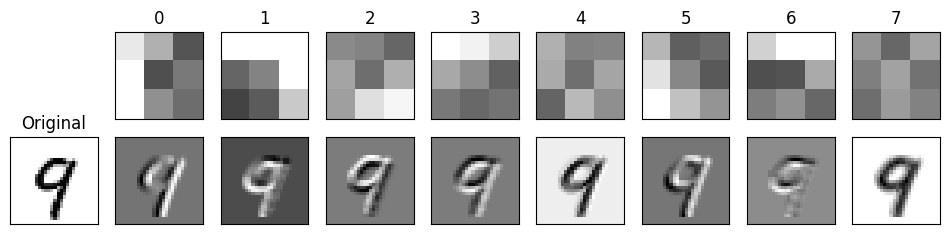

In [25]:
# week12_7.txt
# 필터 리스트
plt.figure(1, figsize = (12, 2.5))
plt.gray()
plt.subplots_adjust(wspace = 0.2, hspace = 0.2)
plt.subplot(2, 9, 10)
id_img = 12
x_img = x_test[id_img, : , : , 0]
img_h = 28
img_w = 28
x_img = x_img.reshape(img_h, img_w)
plt.pcolor(-x_img)
plt.xlim(0, img_h)
plt.ylim(img_w, 0)
plt.xticks([], "")
plt.yticks([], "")
plt.title("Original")

w = model_cnn.layers[0].get_weights()[0]
max_w = np.max(w)
min_w = np.min(w)

for i in range(8):
    plt.subplot(2, 9, i + 2)
    w1 = w[:, :, 0, i]
    w1 = w1.reshape(3, 3)
    plt.pcolor(-w1, vmin = min_w, vmax = max_w)
    plt.xlim(0, 3)
    plt.ylim(3, 0)
    plt.xticks([], "")
    plt.yticks([], "")
    plt.title("%d" %i)
    
    # 필터 처리
    plt.subplot(2, 9, i + 11)
    out_img = np.zeros_like(x_img)
    
    for ih in range(img_h - 3):
        for iw in range(img_w - 3):
            img_part = x_img[ih : ih + 3, iw: iw +3]
            out_img[ih + 1, iw + 1] = np.dot(img_part.reshape(-1), w1.reshape(-1))
    
    plt.pcolor(-out_img)
    plt.xlim(0, img_w)
    plt.ylim(img_h, 0)
    plt.xticks([], "")
    plt.yticks([], "")

plt.show()

In [26]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam
np.random.seed(1)
model_cnn_2 = Sequential()
model_cnn_2.add(Conv2D(16, (3, 3), input_shape=(28, 28, 1), padding='same', activation='relu'))
model_cnn_2.add(Conv2D(32, (3, 3), padding='same', activation='relu'))
model_cnn_2.add(MaxPooling2D(pool_size=(2,2)))  # 최대 풀링층 2×2
model_cnn_2.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
model_cnn_2.add(MaxPooling2D(pool_size=(2,2)))  # 최대 풀링층 2×2
model_cnn_2.add(Dropout(0.25))  # Dropout 수행으로 0.25는 남은 뉴런의 비율을 의미
model_cnn_2.add(Flatten())
model_cnn_2.add(Dense(128, activation='relu'))
model_cnn_2.add(Dropout(0.25))  # Dropout
model_cnn_2.add(Dense(num_classes, activation='softmax'))
model_cnn_2.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])

In [27]:
model_cnn_2.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_1 (Conv2D)           (None, 28, 28, 16)        160       
                                                                 
 conv2d_2 (Conv2D)           (None, 28, 28, 32)        4640      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 14, 14, 32)       0         
 )                                                               
                                                                 
 conv2d_3 (Conv2D)           (None, 14, 14, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 7, 7, 64)         0         
 2D)                                                             
                                                                 
 dropout (Dropout)           (None, 7, 7, 64)         

In [28]:
import time
start_time = time.time()
history = model_cnn_2.fit(x_train, y_train, batch_size=1000, epochs=30, verbose=1,
                           validation_data=(x_test, y_test))
print("Computation time:{:.3f} sec".format(time.time() - start_time))

Epoch 1/30
60/60 [==============================] - 15s 246ms/step - loss: 0.6467 - accuracy: 0.8017 - val_loss: 0.1308 - val_accuracy: 0.9602
Epoch 2/30
60/60 [==============================] - 15s 248ms/step - loss: 0.1345 - accuracy: 0.9587 - val_loss: 0.0644 - val_accuracy: 0.9785
Epoch 3/30
60/60 [==============================] - 15s 243ms/step - loss: 0.0873 - accuracy: 0.9734 - val_loss: 0.0495 - val_accuracy: 0.9831
Epoch 4/30
60/60 [==============================] - 15s 253ms/step - loss: 0.0696 - accuracy: 0.9785 - val_loss: 0.0380 - val_accuracy: 0.9871
Epoch 5/30
60/60 [==============================] - 15s 250ms/step - loss: 0.0576 - accuracy: 0.9819 - val_loss: 0.0336 - val_accuracy: 0.9881
Epoch 6/30
60/60 [==============================] - 15s 249ms/step - loss: 0.0476 - accuracy: 0.9853 - val_loss: 0.0311 - val_accuracy: 0.9887
Epoch 7/30
60/60 [==============================] - 15s 254ms/step - loss: 0.0433 - accuracy: 0.9874 - val_loss: 0.0255 - val_accuracy: 0.9906

In [29]:
score = model_cnn_2.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

Test loss: 0.018027901649475098
Test accuracy: 0.9944000244140625


313/313 [==============================] - 3s 10ms/step
Total wrong answer:  1 / 96


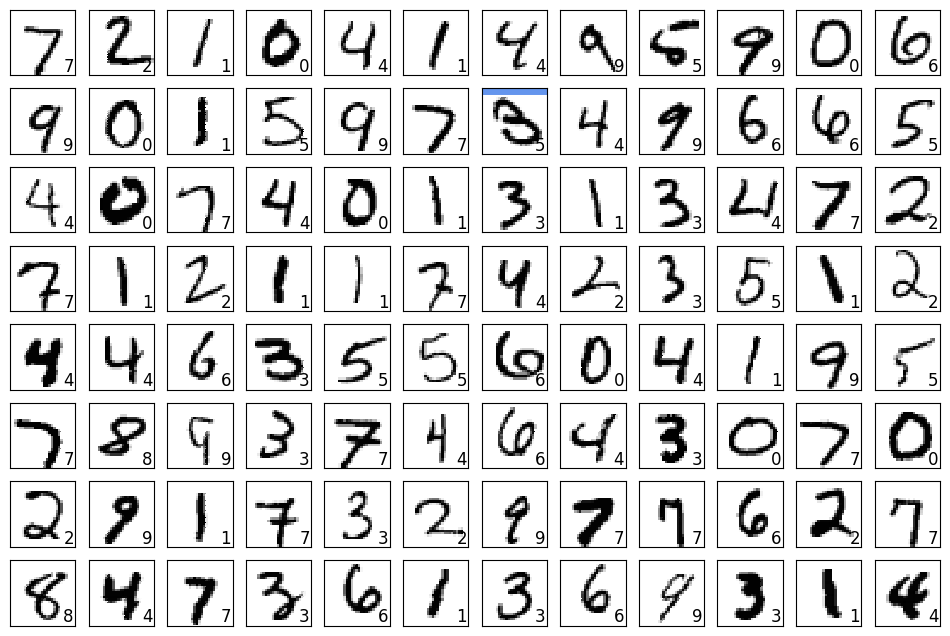

In [30]:
# week12_8.txt
# 실제 테스트 데이터를 입력했을 때 모델의 출력
def show_prediction():
    n_show = 96
    y = model_cnn_2.predict(x_test)
    plt.figure(2, figsize = (12, 8))
    plt.gray()
    wrong_answer = 0
    for i in range(n_show):
        plt.subplot(8, 12, i + 1)
        x = x_test[i, :]
        x = x.reshape(28, 28)
        plt.pcolor(1 - x)
        wk = y[i, :]
        prediction = np.argmax(wk)
        plt.text(22, 25.5, "%d" % prediction, fontsize = 12)
        
        if prediction != np.argmax(y_test[i, :]):
            plt.plot([0, 27], [1, 1], color ='cornflowerblue', linewidth = 5)
            wrong_answer = wrong_answer + 1
            
        plt.xlim(0, 27)
        plt.ylim(27, 0)
        plt.xticks([], "")
        plt.yticks([], "")
    print("Total wrong answer: {0: d} / 96" .format(wrong_answer))
        
# 메인
show_prediction()
plt.show()